<a href="https://colab.research.google.com/github/keyvanmahmoudi/Deep_Learning_Course/blob/main/sessions/Session07_convolutional_networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۷: شبکه‌های عصبی کانولوشنی (CNN)

### اهداف این جلسه

- درک محدودیت‌های MLP برای داده تصویری
- پیاده‌سازی عملیات کانولوشن از صفر و دیدن اثر فیلترهای لبه‌یاب
- تسلط بر مفاهیم Kernel، Stride، Padding، کانال‌ها و فرمول ابعاد خروجی
- آشنایی با Pooling و میدان دید (Receptive Field)
- ساخت و آموزش CNN روی Fashion-MNIST و CIFAR-10 و مقایسه با MLP
- نمایش فیلترهای یادگرفته‌شده و Feature Mapها

> **نکتهٔ اجرا:** این نوت‌بوک روی GPU بسیار سریع‌تر اجرا می‌شود. در Colab از منوی `Runtime → Change runtime type` گزینهٔ **T4 GPU** را انتخاب کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۱. چرا MLP برای تصویر مناسب نیست؟

در جلسه ۴ دیدیم که MLP روی Fashion-MNIST به حدود ۸۸٪ دقت می‌رسد. اما این روش سه مشکل اساسی دارد:

۱. **تعداد پارامتر زیاد:** یک تصویر رنگی ۲۲۴×۲۲۴ بیش از ۱۵۰ هزار ورودی دارد؛ فقط یک لایه پنهان با ۱۰۰۰ نورون حدود ۱۵۰ میلیون وزن لازم دارد.

۲. **نادیده گرفتن ساختار فضایی:** با `Flatten` پیکسل‌های همسایه دیگر همسایه نیستند. اگر ترتیب پیکسل‌ها را (برای همه تصاویر به یک شکل) به هم بریزیم، MLP هیچ تفاوتی حس نمی‌کند!

۳. **عدم تغییرناپذیری نسبت به جابه‌جایی (Translation Invariance):** الگویی که MLP در گوشه بالای تصویر یاد گرفته، در گوشه پایین شناخته نمی‌شود؛ چون وزن‌های متفاوتی دارد.

**شبکه‌های عصبی کانولوشنی (Convolutional Neural Networks, CNN)** با دو ایده این مشکلات را حل می‌کنند:

- **اتصال محلی (Local Connectivity):** هر نورون فقط به یک ناحیه کوچک از ورودی نگاه می‌کند.
- **اشتراک وزن (Weight Sharing):** یک فیلتر کوچک روی **همه** مکان‌های تصویر می‌لغزد؛ پس الگو در هر جای تصویر شناخته می‌شود.

ایده CNN از ساختار قشر بینایی مغز الهام گرفته شده (Hubel & Wiesel) و اولین CNN موفق، LeNet-5 لِکان (LeCun et al., 1998) برای خواندن ارقام دست‌نویس چک‌های بانکی بود.

</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
torch.manual_seed(42)

device: cpu


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۲. عملیات کانولوشن

در کانولوشن دوبعدی، یک **کرنل (Kernel)** یا **فیلتر** کوچک (مثلاً ۳×۳) روی تصویر می‌لغزد. در هر مکان، حاصل‌ضرب عنصربه‌عنصر کرنل و ناحیه زیر آن جمع زده می‌شود و یک عدد از **نقشه ویژگی (Feature Map)** خروجی را می‌سازد:

$$Y[i, j] = \sum_{m}\sum_{n} X[i+m,\ j+n]\; K[m, n] + b$$

(از نظر ریاضی دقیق، این عملیات **Cross-Correlation** است؛ در یادگیری عمیق به آن کانولوشن می‌گوییم چون کرنل یادگرفتنی است و قرینه کردن آن فرقی نمی‌کند.)

پیاده‌سازی از صفر با دو حلقه:

</div>

In [2]:
def conv2d_naive(image, kernel):
    """'Valid' 2-D cross-correlation of a single-channel image with a single kernel."""
    H, W = image.shape
    kh, kw = kernel.shape
    out = np.zeros((H - kh + 1, W - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = np.sum(image[i:i + kh, j:j + kw] * kernel)
    return out


# a hand-designed example: a vertical edge
img = np.zeros((6, 6)); img[:, 3:] = 1
k_vertical = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]])
print('image:\n', img)
print('feature map (vertical-edge kernel):\n', conv2d_naive(img, k_vertical))

image:
 [[0. 0. 0. 1. 1. 1.]
 [0. 0. 0. 1. 1. 1.]
 [0. 0. 0. 1. 1. 1.]
 [0. 0. 0. 1. 1. 1.]
 [0. 0. 0. 1. 1. 1.]
 [0. 0. 0. 1. 1. 1.]]
feature map (vertical-edge kernel):
 [[ 0. -3. -3.  0.]
 [ 0. -3. -3.  0.]
 [ 0. -3. -3.  0.]
 [ 0. -3. -3.  0.]]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

فیلتر لبه عمودی فقط در جایی که روشنایی در جهت افقی تغییر می‌کند پاسخ قوی می‌دهد. حالا فیلترهای کلاسیک **Sobel** را روی یک تصویر واقعی از Fashion-MNIST اعمال می‌کنیم:

</div>

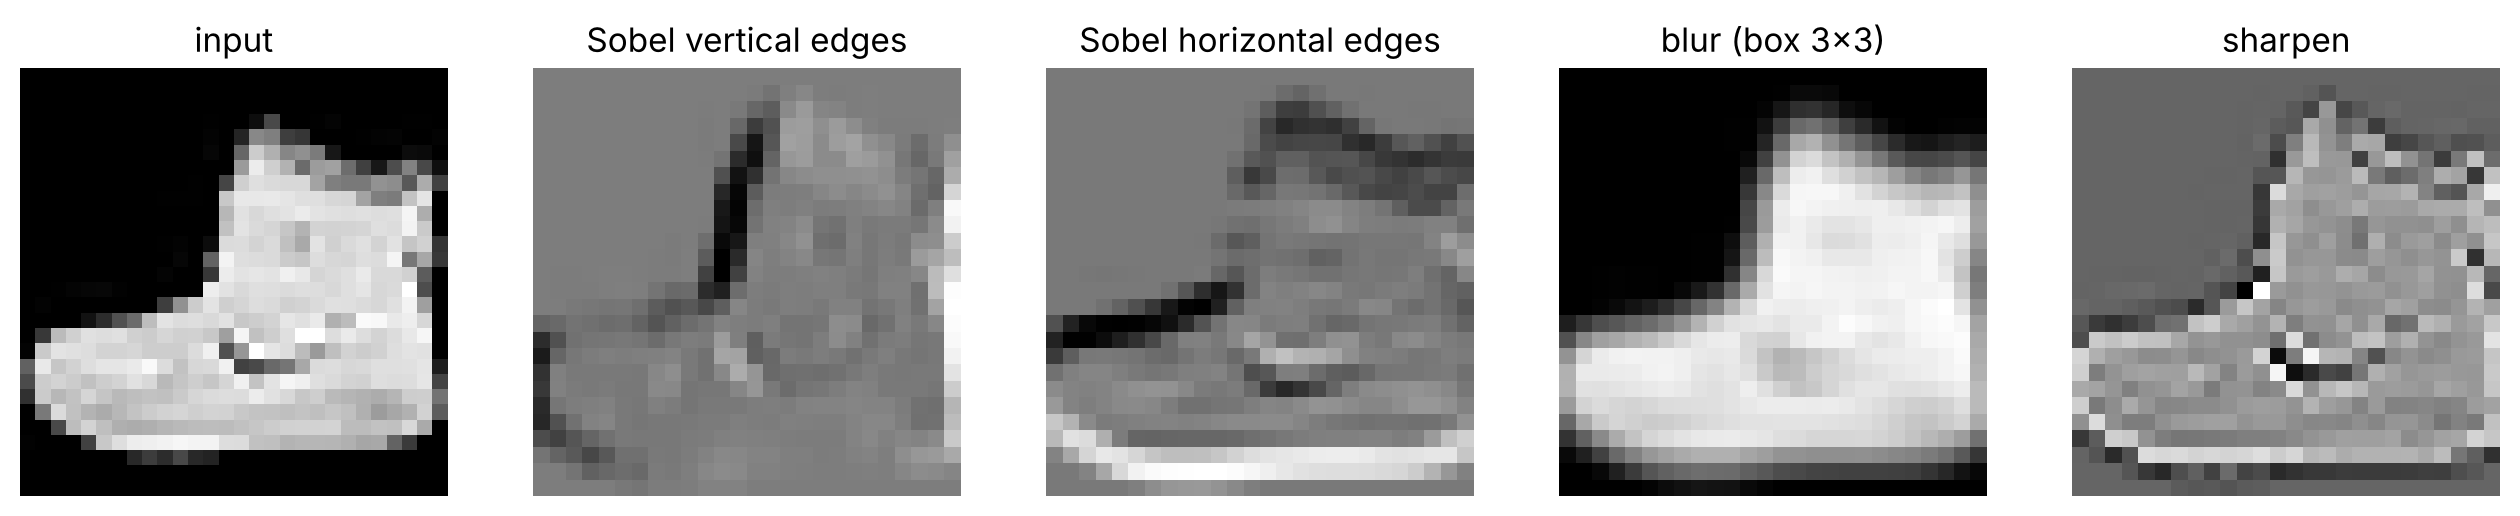

In [3]:
raw = datasets.FashionMNIST('data', train=True, download=True)
sample = np.array(raw[0][0], dtype=np.float32) / 255.0

kernels = {
    'Sobel vertical edges': np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]]),
    'Sobel horizontal edges': np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]]),
    'blur (box 3x3)': np.ones((3, 3)) / 9,
    'sharpen': np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
}
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
axes[0].imshow(sample, cmap='gray'); axes[0].set_title('input')
for ax, (name, k) in zip(axes[1:], kernels.items()):
    ax.imshow(conv2d_naive(sample, k), cmap='gray'); ax.set_title(name)
for ax in axes:
    ax.axis('off')
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

در بینایی ماشین کلاسیک این فیلترها دستی طراحی می‌شدند. در CNN **مقادیر کرنل‌ها پارامترهای قابل آموزش‌اند** و شبکه خودش با Backpropagation یاد می‌گیرد چه فیلترهایی برای مسئله مفیدند.

## ۳. ابعاد: Stride، Padding و کانال‌ها

- **Padding ($p$):** افزودن صفر دور تصویر تا ابعاد خروجی کم نشود و لبه‌ها هم به‌اندازه کافی دیده شوند. با کرنل $k\times k$ و $p = (k-1)/2$ ابعاد حفظ می‌شود (`padding='same'`).
- **Stride ($s$):** فاصله گام‌های لغزش. با $s=2$ ابعاد خروجی تقریباً نصف می‌شود.
- **ابعاد خروجی:**

$$H_{\text{out}} = \left\lfloor \frac{H_{\text{in}} + 2p - k}{s} \right\rfloor + 1$$

- **کانال‌ها:** ورودی رنگی سه کانال (RGB) دارد. هر فیلتر در عمل یک تنسور $C_{\text{in}} \times k \times k$ است که روی **همه کانال‌ها** اعمال و جمع می‌شود. لایه‌ای با $C_{\text{out}}$ فیلتر، $C_{\text{out}}$ نقشه ویژگی تولید می‌کند.
- **تعداد پارامتر یک لایه کانولوشنی:** $C_{\text{out}} \times (C_{\text{in}} \times k \times k + 1)$؛ مستقل از اندازه تصویر!

در PyTorch، `nn.Conv2d` ورودی با شکل `(N, C_in, H, W)` می‌گیرد:

</div>

In [4]:
def conv_out(h, k, s=1, p=0):
    return (h + 2 * p - k) // s + 1


x = torch.randn(8, 3, 32, 32)            # a batch of 8 RGB images, 32x32
for k, s, p in [(3, 1, 0), (3, 1, 1), (5, 1, 2), (3, 2, 1), (7, 2, 3)]:
    conv = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=k, stride=s, padding=p)
    y = conv(x)
    n_params = sum(t.numel() for t in conv.parameters())
    print(f'k={k} s={s} p={p}: output {tuple(y.shape)} | formula H_out = {conv_out(32, k, s, p)} | parameters = {n_params}')

k=3 s=1 p=0: output (8, 16, 30, 30) | formula H_out = 30 | parameters = 448
k=3 s=1 p=1: output (8, 16, 32, 32) | formula H_out = 32 | parameters = 448
k=5 s=1 p=2: output (8, 16, 32, 32) | formula H_out = 32 | parameters = 1216
k=3 s=2 p=1: output (8, 16, 16, 16) | formula H_out = 16 | parameters = 448
k=7 s=2 p=3: output (8, 16, 16, 16) | formula H_out = 16 | parameters = 2368


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

لایه کانولوشنی با ۱۶ فیلتر ۳×۳ روی تصویر رنگی فقط $16\times(3\times3\times3+1) = 448$ پارامتر دارد، در حالی که یک لایه Linear از همین ورودی به همان خروجی ($16\times32\times32$) بیش از ۵۰ میلیون پارامتر لازم داشت.

## ۴. Pooling و میدان دید (Receptive Field)

**Pooling** ابعاد مکانی نقشه‌های ویژگی را کاهش می‌دهد (Downsampling):

- **Max Pooling:** بیشینه هر ناحیه (معمولاً ۲×۲ با Stride ۲). رایج‌ترین نوع؛ وجود یک ویژگی را در ناحیه حفظ می‌کند.
- **Average Pooling:** میانگین هر ناحیه. نسخه سراسری آن (**Global Average Pooling**) در انتهای CNNهای مدرن به‌جای Flatten استفاده می‌شود.

Pooling پارامتر ندارد، محاسبات لایه‌های بعدی را کم می‌کند و مدل را نسبت به جابه‌جایی‌های کوچک مقاوم‌تر می‌کند.

</div>

In [5]:
fm = torch.tensor([[1., 3, 2, 1], [4, 6, 5, 0], [3, 1, 1, 2], [0, 2, 7, 4]]).view(1, 1, 4, 4)
print('input:\n', fm.squeeze())
print('max pool 2x2:\n', F.max_pool2d(fm, 2).squeeze())
print('avg pool 2x2:\n', F.avg_pool2d(fm, 2).squeeze())

input:
 tensor([[1., 3., 2., 1.],
        [4., 6., 5., 0.],
        [3., 1., 1., 2.],
        [0., 2., 7., 4.]])
max pool 2x2:
 tensor([[6., 5.],
        [3., 7.]])
avg pool 2x2:
 tensor([[3.5000, 2.0000],
        [1.5000, 3.5000]])


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**میدان دید (Receptive Field)** ناحیه‌ای از تصویر ورودی است که روی یک نورون اثر می‌گذارد. یک لایه ۳×۳ میدان دید ۳×۳ دارد؛ دو لایه ۳×۳ پشت سر هم ۵×۵؛ و هر Pooling میدان دید لایه‌های بعدی را دو برابر می‌کند. به همین دلیل CNNها **سلسله‌مراتبی** یاد می‌گیرند: لایه‌های اول لبه‌ها و بافت‌ها، لایه‌های میانی اجزا (مثل یقه یا پاشنه کفش) و لایه‌های آخر کل شیء.

## ۵. اولین CNN روی Fashion-MNIST

ساختار رایج یک CNN: چند **بلوک کانولوشنی** (Conv → BatchNorm → ReLU → Pool) که ابعاد مکانی را کم و تعداد کانال‌ها را زیاد می‌کنند، و در انتها یک **طبقه‌بند** (Classifier) از لایه‌های Linear.

</div>

In [6]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.2860,), (0.3530,))])
full_train = datasets.FashionMNIST('data', train=True, download=True, transform=transform)
test_set = datasets.FashionMNIST('data', train=False, download=True, transform=transform)
train_set, val_set = random_split(full_train, [50_000, 10_000], generator=torch.Generator().manual_seed(42))
CLASSES = full_train.classes

train_loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=512, num_workers=2)
test_loader = DataLoader(test_set, batch_size=512, num_workers=2)

In [7]:
def train_one_epoch(model, loader, criterion, optimizer, device, scheduler=None):
    """One pass over the training data. `scheduler` is stepped after every batch if given."""
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        loss = criterion(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if scheduler is not None:
            scheduler.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        total_loss += criterion(logits, y).item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def fit(model, train_loader, val_loader, optimizer, epochs, device, scheduler=None, verbose=True):
    """Train for `epochs` epochs and return the history of losses and accuracies."""
    criterion = nn.CrossEntropyLoss()
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    for epoch in range(1, epochs + 1):
        tr = train_one_epoch(model, train_loader, criterion, optimizer, device, scheduler)
        va = evaluate(model, val_loader, criterion, device)
        for k, v in zip(history, (*tr, *va)):
            history[k].append(v)
        if verbose:
            print(f'epoch {epoch:2d} | train loss {tr[0]:.4f} acc {tr[1]:.4f} | val loss {va[0]:.4f} acc {va[1]:.4f}')
    return history

In [8]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.Conv2d(c_out, c_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )


class SimpleCNN(nn.Module):
    def __init__(self, in_channels=1, n_classes=10, img_size=28):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(in_channels, 32),      # 28x28 -> 14x14
            conv_block(32, 64),               # 14x14 -> 7x7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64 * (img_size // 4) ** 2, 128),
            nn.ReLU(),
            nn.Linear(128, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


cnn = SimpleCNN().to(device)
x = torch.randn(2, 1, 28, 28).to(device)
for name, layer in [('input', None), ('block 1', cnn.features[0]), ('block 2', cnn.features[1])]:
    if layer is not None:
        x = layer(x)
    print(f'{name:8s} -> {tuple(x.shape)}')
print(f'CNN parameters: {sum(p.numel() for p in cnn.parameters()):,}')

input    -> (2, 1, 28, 28)
block 1  -> (2, 32, 14, 14)
block 2  -> (2, 64, 7, 7)
CNN parameters: 468,202


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

این CNN حدود ۴۶۸ هزار پارامتر دارد که بیش از ۴۰۰ هزار تای آن‌ها در لایه Linear اول طبقه‌بند است؛ چهار لایه کانولوشنی روی هم فقط حدود ۶۵ هزار پارامتر دارند. آموزش با AdamW و زمان‌بند OneCycle (جلسه ۵):

</div>

In [9]:
EPOCHS = 10
torch.manual_seed(0)
cnn = SimpleCNN().to(device)
optimizer = torch.optim.AdamW(cnn.parameters(), lr=1e-3, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=3e-3, epochs=EPOCHS, steps_per_epoch=len(train_loader))
history = fit(cnn, train_loader, val_loader, optimizer, EPOCHS, device, scheduler=scheduler)

criterion = nn.CrossEntropyLoss()
print(f'\nCNN test accuracy: {evaluate(cnn, test_loader, criterion, device)[1]:.4f}')

epoch  1 | train loss 0.5025 acc 0.8245 | val loss 0.3609 acc 0.8777


epoch  2 | train loss 0.3187 acc 0.8837 | val loss 0.2776 acc 0.9008


epoch  3 | train loss 0.2642 acc 0.9038 | val loss 0.2385 acc 0.9129


epoch  4 | train loss 0.2175 acc 0.9193 | val loss 0.2352 acc 0.9154


epoch  5 | train loss 0.1913 acc 0.9278 | val loss 0.1957 acc 0.9296


epoch  6 | train loss 0.1589 acc 0.9417 | val loss 0.1859 acc 0.9310


epoch  7 | train loss 0.1304 acc 0.9514 | val loss 0.1918 acc 0.9341


epoch  8 | train loss 0.1010 acc 0.9626 | val loss 0.1746 acc 0.9384


epoch  9 | train loss 0.0736 acc 0.9735 | val loss 0.1746 acc 0.9409


epoch 10 | train loss 0.0614 acc 0.9789 | val loss 0.1741 acc 0.9423



CNN test accuracy: 0.9381


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

CNN دقت آزمون را از حدود ۸۸٪ (MLP جلسه ۴) به حدود ۹۴٪ می‌رساند و خطاهای بین کلاس‌های مشابه (Shirt، T-shirt، Coat) را به‌طور محسوسی کم می‌کند. تعداد پارامترهای این CNN (حدود ۴۶۸ هزار) دو برابر MLP است، اما بیشتر آن‌ها در لایه Linear طبقه‌بند است و کار اصلی را لایه‌های کانولوشنی با فقط ۶۵ هزار پارامتر انجام می‌دهند.

### آزمون جابه‌جایی: CNN در برابر MLP

برای دیدن اثر اشتراک وزن، تصاویر آزمون را چند پیکسل جابه‌جا می‌کنیم و دقت دو مدل را می‌سنجیم. یک MLP هم سریع آموزش می‌دهیم:

</div>

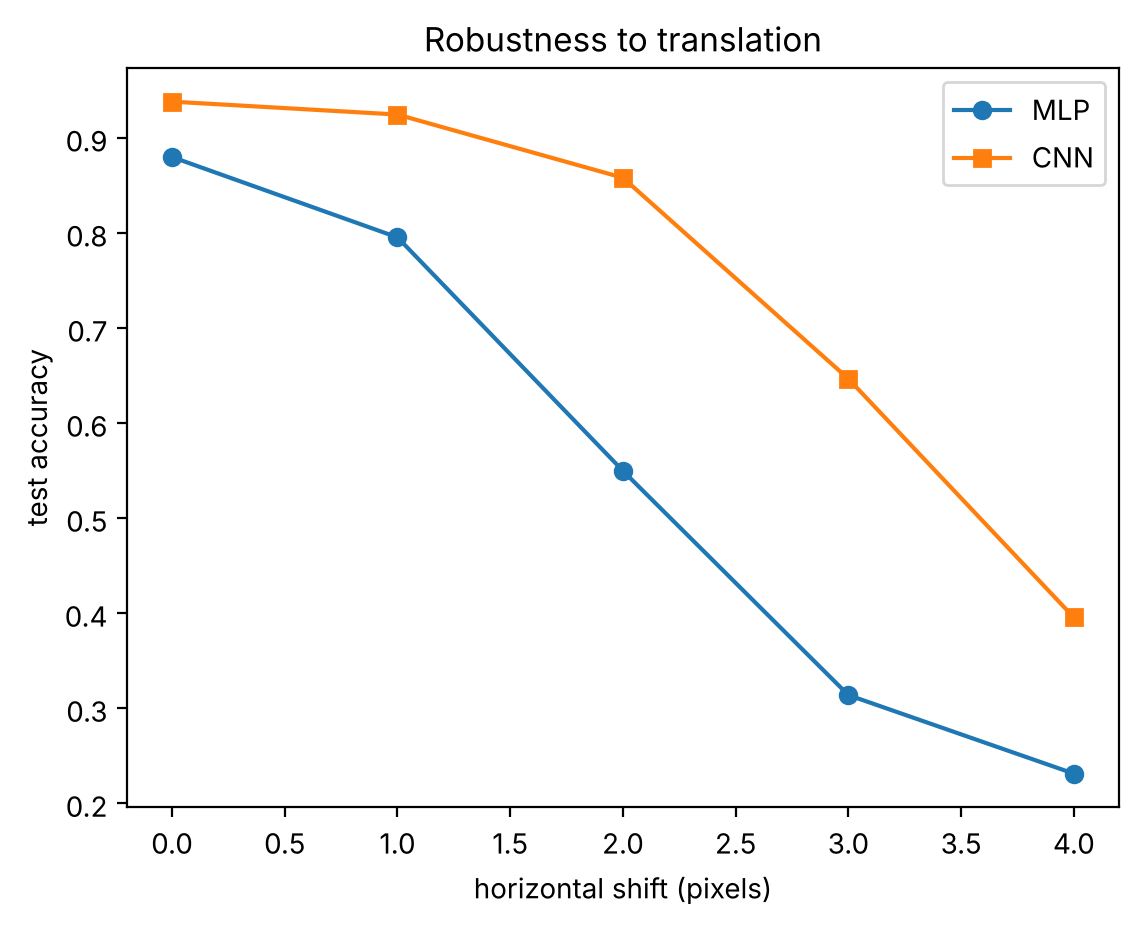

MLP: [0.88  0.795 0.55  0.314 0.231] 
CNN: [0.938 0.924 0.858 0.646 0.396]


In [10]:
torch.manual_seed(0)
mlp = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 10)).to(device)
fit(mlp, train_loader, val_loader, torch.optim.AdamW(mlp.parameters(), lr=1e-3), 5, device, verbose=False)


@torch.no_grad()
def shifted_accuracy(model, loader, shift):
    model.eval()
    correct = n = 0
    for X, y in loader:
        X = torch.roll(X, shifts=shift, dims=3).to(device)     # shift right by `shift` pixels
        correct += (model(X).argmax(1).cpu() == y).sum().item(); n += len(y)
    return correct / n


shifts = [0, 1, 2, 3, 4]
acc_mlp = [shifted_accuracy(mlp, test_loader, s) for s in shifts]
acc_cnn = [shifted_accuracy(cnn, test_loader, s) for s in shifts]
plt.plot(shifts, acc_mlp, 'o-', label='MLP'); plt.plot(shifts, acc_cnn, 's-', label='CNN')
plt.xlabel('horizontal shift (pixels)'); plt.ylabel('test accuracy'); plt.legend(); plt.title('Robustness to translation')
plt.show()
print('MLP:', np.round(acc_mlp, 3), '\nCNN:', np.round(acc_cnn, 3))

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

دقت هر دو مدل با جابه‌جایی کم می‌شود (هیچ‌کدام با جابه‌جایی آموزش ندیده‌اند)، اما CNN بسیار مقاوم‌تر است. با Data Augmentation (جلسه ۶) این مقاومت بیشتر هم می‌شود.

## ۶. درون CNN چه می‌گذرد؟

### فیلترهای لایه اول

فیلترهای لایه اول مستقیماً روی پیکسل‌ها اعمال می‌شوند و قابل نمایش‌اند. معمولاً شبیه آشکارسازهای لبه و بافت در جهت‌های مختلف هستند:

</div>

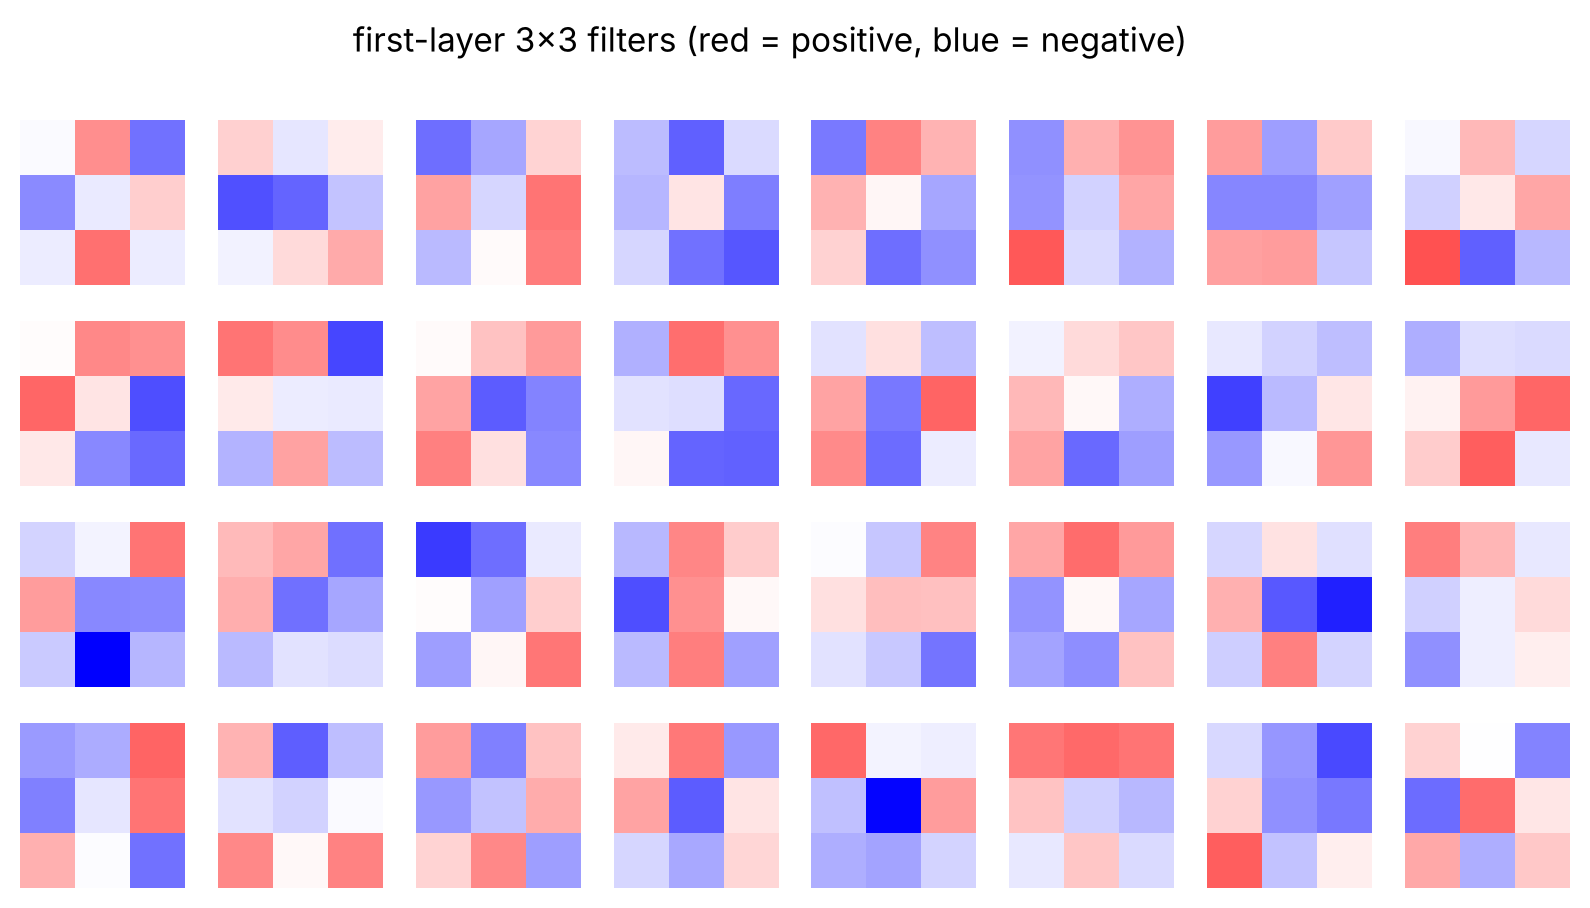

In [11]:
w = cnn.features[0][0].weight.detach().cpu()        # shape (32, 1, 3, 3)
fig, axes = plt.subplots(4, 8, figsize=(10, 5))
for ax, k in zip(axes.flat, w):
    ax.imshow(k[0], cmap='bwr', vmin=-w.abs().max(), vmax=w.abs().max())
    ax.axis('off')
plt.suptitle('first-layer 3x3 filters (red = positive, blue = negative)'); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### نقشه‌های ویژگی (Feature Maps)

با یک **Forward Hook** می‌توانیم خروجی لایه‌های میانی را هنگام عبور یک تصویر ذخیره کنیم:

</div>

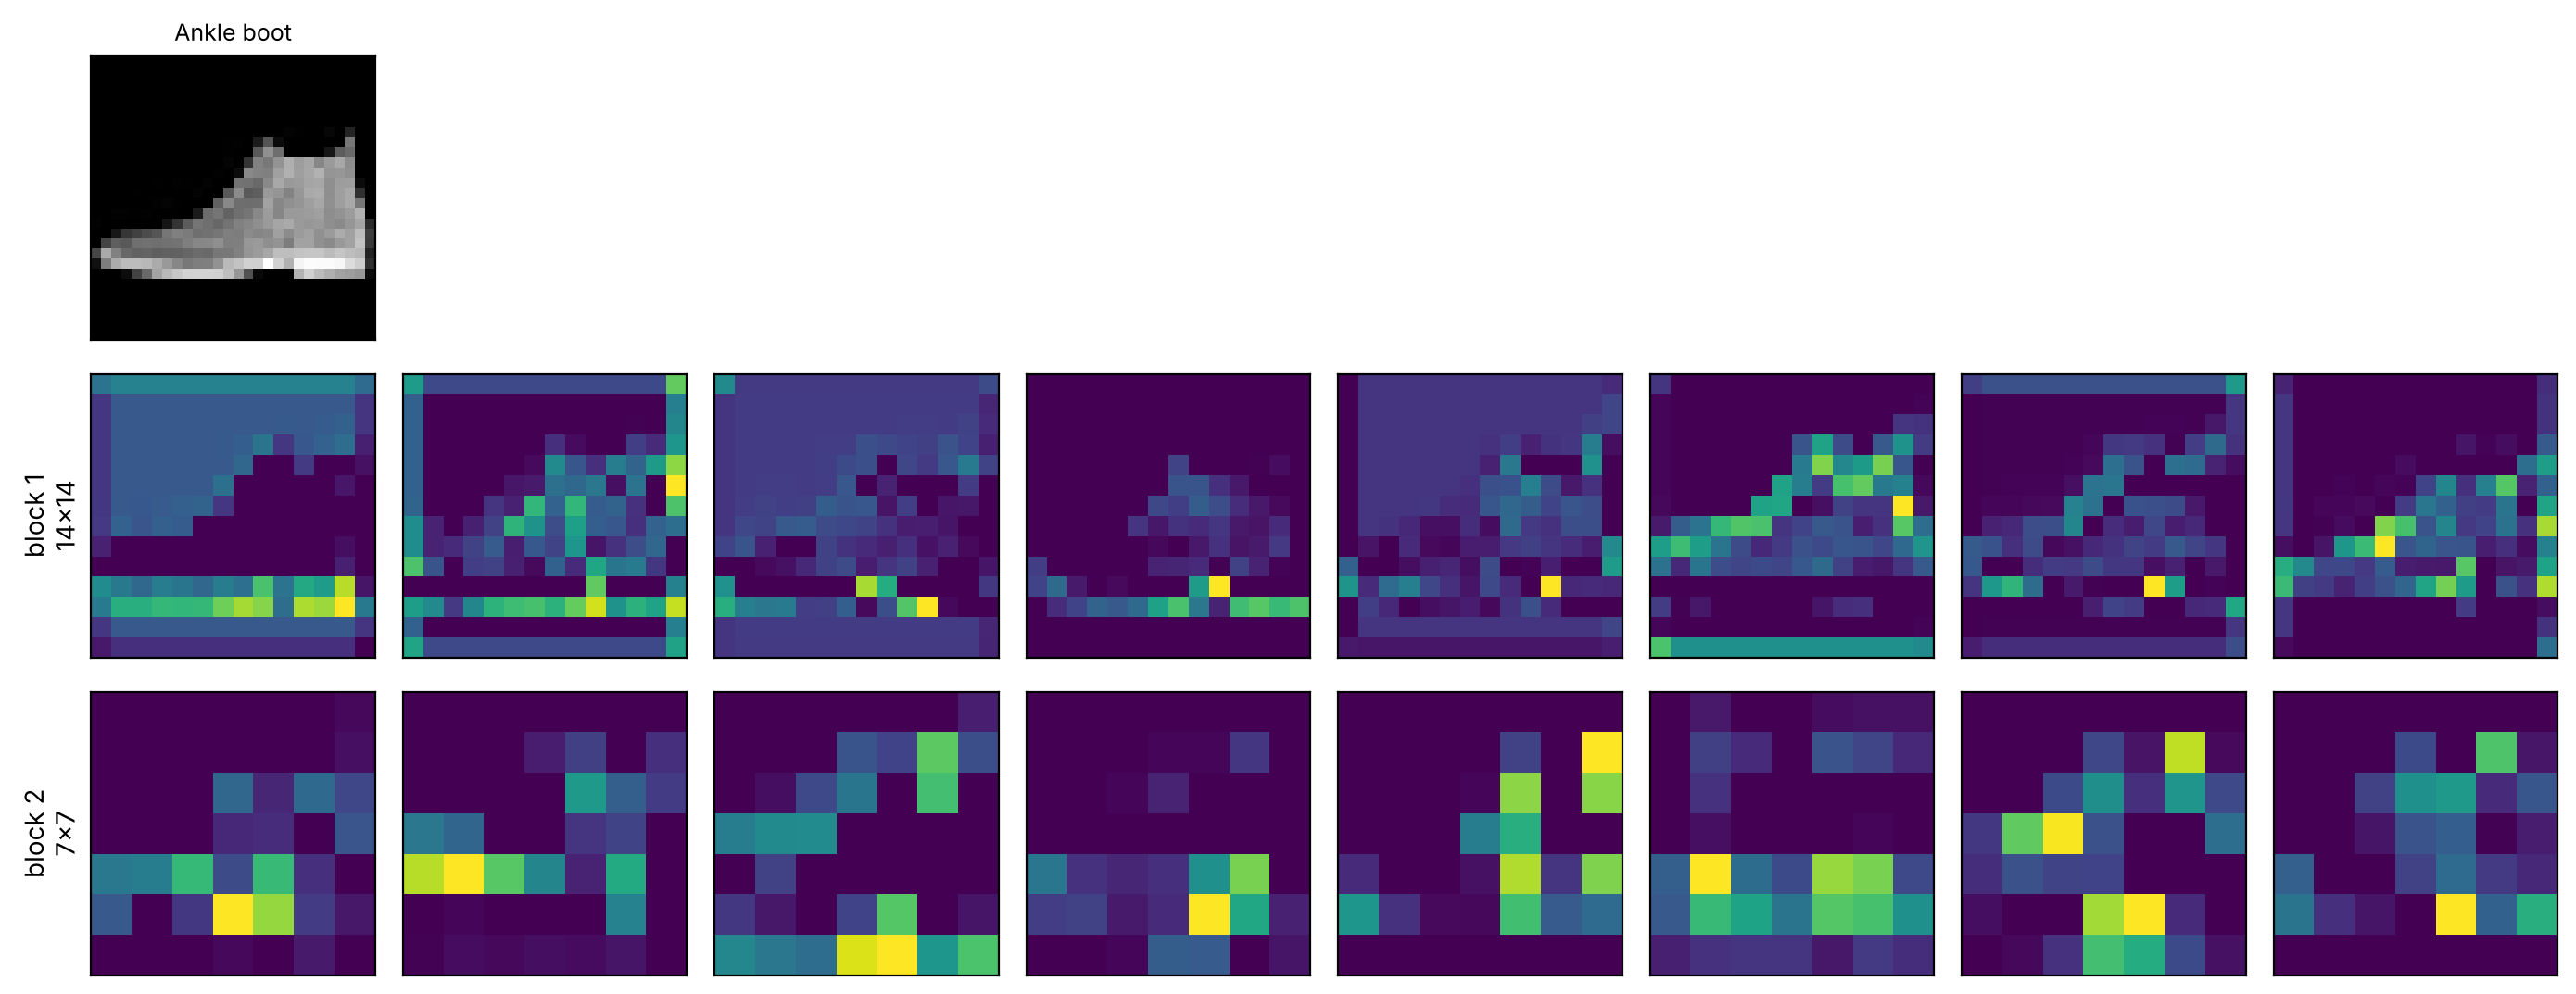

In [12]:
activations = {}

def save_output(name):
    def hook(module, inputs, output):
        activations[name] = output.detach().cpu()
    return hook


h1 = cnn.features[0].register_forward_hook(save_output('block1'))
h2 = cnn.features[1].register_forward_hook(save_output('block2'))
image, label = test_set[0]
cnn.eval()
with torch.no_grad():
    cnn(image.unsqueeze(0).to(device))
h1.remove(); h2.remove()                              # always remove hooks when done

fig, axes = plt.subplots(3, 8, figsize=(14, 5.5))
axes[0, 0].imshow(image[0], cmap='gray'); axes[0, 0].set_title(CLASSES[label], fontsize=9)
for j in range(1, 8):
    axes[0, j].axis('off')
for j in range(8):
    axes[1, j].imshow(activations['block1'][0, j], cmap='viridis')
    axes[2, j].imshow(activations['block2'][0, j], cmap='viridis')
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
axes[1, 0].set_ylabel('block 1\n14x14'); axes[2, 0].set_ylabel('block 2\n7x7')
plt.tight_layout(); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

نقشه‌های بلوک اول هنوز شبیه تصویر ورودی‌اند (لبه‌ها و نواحی روشن و تیره). نقشه‌های بلوک دوم انتزاعی‌ترند و هر کدام به حضور یک ویژگی سطح بالاتر در نواحی مختلف حساس است.

## ۷. تصاویر رنگی: CIFAR-10

**CIFAR-10** (Krizhevsky, 2009) شامل ۶۰٬۰۰۰ تصویر رنگی ۳۲×۳۲ در ۱۰ کلاس (هواپیما، خودرو، پرنده، گربه، …) است و بسیار سخت‌تر از Fashion-MNIST است: اشیاء در پس‌زمینه‌های متنوع، زاویه‌ها و رنگ‌های مختلف ظاهر می‌شوند. همان معماری را با سه کانال ورودی و Data Augmentation آموزش می‌دهیم. **این بخش را با GPU اجرا کنید.**

</div>

In [ ]:
CIFAR_MEAN, CIFAR_STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
test_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(CIFAR_MEAN, CIFAR_STD)])

cifar_train = datasets.CIFAR10('data', train=True, download=True, transform=train_tf)
cifar_test = datasets.CIFAR10('data', train=False, download=True, transform=test_tf)
CIFAR_CLASSES = cifar_train.classes
cifar_train_loader = DataLoader(cifar_train, batch_size=128, shuffle=True, num_workers=2)
cifar_test_loader = DataLoader(cifar_test, batch_size=512, num_workers=2)
print('CIFAR-10 classes:', CIFAR_CLASSES)

show = datasets.CIFAR10('data', train=True, download=True)
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axes.flat, range(16)):
    img, lab = show[i]
    ax.imshow(img); ax.set_title(CIFAR_CLASSES[lab], fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
class CifarCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 64),       # 32 -> 16
            conv_block(64, 128),     # 16 -> 8
            conv_block(128, 256),    # 8 -> 4
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),  # global average pooling: (N, 256, 4, 4) -> (N, 256, 1, 1)
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


CIFAR_EPOCHS = 15
torch.manual_seed(0)
cifar_model = CifarCNN().to(device)
print(f'parameters: {sum(p.numel() for p in cifar_model.parameters()):,}')
optimizer = torch.optim.AdamW(cifar_model.parameters(), lr=1e-3, weight_decay=5e-2)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=3e-3, epochs=CIFAR_EPOCHS, steps_per_epoch=len(cifar_train_loader))
cifar_history = fit(cifar_model, cifar_train_loader, cifar_test_loader, optimizer, CIFAR_EPOCHS, device, scheduler=scheduler)

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

در این بخش برای سادگی از داده آزمون به‌عنوان داده اعتبارسنجی استفاده کردیم چون ابرپارامتری را تنظیم نمی‌کنیم؛ در یک پروژه واقعی باید مثل قبل یک Validation Set جدا کنید.

دقت را روی داده آزمون بررسی کنید و با مدل‌های جلسه بعد مقایسه کنید. برای رسیدن به دقت‌های بالاتر به معماری‌های عمیق‌تر نیاز داریم؛ اما شبکه‌های خیلی عمیق به‌سادگی آموزش نمی‌بینند. راه‌حل این مشکل، یعنی **ResNet**، موضوع جلسه بعد است.

## جمع‌بندی

- CNN با **اتصال محلی** و **اشتراک وزن** پارامترها را به‌شدت کم و ساختار فضایی تصویر را حفظ می‌کند.
- کانولوشن = لغزاندن فیلتر یادگرفتنی روی تصویر؛ هر فیلتر یک Feature Map می‌سازد.
- ابعاد خروجی: $\lfloor (H + 2p - k)/s \rfloor + 1$؛ تعداد پارامتر: $C_{\text{out}}(C_{\text{in}}k^2 + 1)$.
- Pooling ابعاد مکانی را کم و میدان دید را زیاد می‌کند؛ Global Average Pooling جایگزین Flatten در CNNهای مدرن است.
- ساختار رایج: بلوک‌های Conv → BatchNorm → ReLU → Pool و سپس طبقه‌بند.
- CNN روی Fashion-MNIST با پارامتر مشابه، از MLP دقیق‌تر و نسبت به جابه‌جایی مقاوم‌تر است.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. تابع `conv2d_naive` را طوری گسترش دهید که `stride` و `padding` را پشتیبانی کند و خروجی آن را با `F.conv2d` مقایسه کنید.

۲. ابعاد خروجی و تعداد پارامترهای هر لایه `CifarCNN` را دستی حساب کنید و با خروجی کد مقایسه کنید.

۳. در `SimpleCNN`، `MaxPool2d` را با کانولوشن با `stride=2` جایگزین کنید. تعداد پارامتر و دقت چه تغییری می‌کند؟

۴. لایه‌های BatchNorm را از `CifarCNN` حذف کنید و منحنی‌های آموزش را با حالت قبل مقایسه کنید.

۵. Confusion Matrix مدل CIFAR-10 را رسم کنید. کدام کلاس‌ها بیشتر با هم اشتباه گرفته می‌شوند؟ آیا منطقی است؟

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** تابع `conv2d_naive` را طوری گسترش دهید که `stride` و `padding` را پشتیبانی کند و خروجی آن را با `F.conv2d` مقایسه کنید.

</div>

In [13]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** ابعاد خروجی و تعداد پارامترهای هر لایه `CifarCNN` را دستی حساب کنید و با خروجی کد مقایسه کنید.

</div>

In [14]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** در `SimpleCNN`، `MaxPool2d` را با کانولوشن با `stride=2` جایگزین کنید. تعداد پارامتر و دقت چه تغییری می‌کند؟

</div>

In [15]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** لایه‌های BatchNorm را از `CifarCNN` حذف کنید و منحنی‌های آموزش را با حالت قبل مقایسه کنید.

</div>

In [16]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۵.** Confusion Matrix مدل CIFAR-10 را رسم کنید. کدام کلاس‌ها بیشتر با هم اشتباه گرفته می‌شوند؟ آیا منطقی است؟

</div>

In [17]:
# پاسخ خود را اینجا بنویسید
